# Addis FTIR EC by season: season or composition? (3 Nov 2026)

Follows `transfer_diagnosis_20261102.ipynb` and reuses its fits, so there is no new calibration here. Models are PLS1 on
12,393 IMPROVE TOR EC filters at k 18 (k 12 for the OC/EC-balanced model), applied unchanged to Addis.

**Yardstick.** Each Addis filter is compared with what IMPROVE TOR would read at the same HIPS loading and OC/BC
(`exp_tor_hips` from the 2 Nov work), not with HIPS/10 at slope 1. A ratio of 1 means "reads like TOR would".

**Calendar.** `local_2026_10` (belg_feb): Bega Oct–Jan, Belg Feb–May, Kiremt Jun–Sep.

**Questions**
1. Is there a seasonal pattern once loading is accounted for?
2. Does it follow composition, and specifically the organic "stand-in" that IMPROVE models learn?
3. Can the organic measure be trusted, given that FTIR OC comes from the same spectrum as FTIR EC?
4. Does the Addis composition relation carry over to Bishoftu?

In [1]:
import sys
sys.path.insert(0, './scripts')
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display
from plotting import PlotConfig  # applies the default white style

T = Path('output/tables/season_composition_20261103')
FIG = Path('output/plots/season_composition_20261103'); FIG.mkdir(parents=True, exist_ok=True)
pd.set_option('display.width', 220); pd.set_option('display.max_columns', 30)
SEASONS = ['Bega', 'Belg', 'Kiremt']
SCOL = {'Bega': '#E67E22', 'Belg': '#27AE60', 'Kiremt': '#3498DB'}  # config.ETHIOPIA_SEASONS hues
MAIN = ['published', 'raw k18', 'anchored k18', 'vibes k18', 'spline k18']
print(json.dumps(json.loads((T / 'receipt.json').read_text()), indent=1))

{
 "source": "research/ftir_hips_chem/output/tables/transfer_diagnosis_20261102",
 "bundle": "/tmp/xfer1102/bundle",
 "models": [
  "published",
  "raw k18",
  "spline k18",
  "vibes k18",
  "anchored k18",
  "anchored_noCH k18",
  "anchored_balanced k12"
 ],
 "calendar": "local_2026_10 (belg_feb)",
 "response": "log(FTIR EC / IMPROVE TOR yardstick)",
 "improve_k": 18,
 "residual_mass": "PM2.5 - 1.375 SO4 - (2.20 Al + 2.49 Si + 2.42 Fe) - HIPS BC (ug/m3), kept if > 0.3",
 "n_addis": 231,
 "n_bishoftu": 21,
 "created": "2026-11-03T08:19:06Z"
}


## 1. The season pattern survives loading

Median FTIR EC relative to the TOR yardstick, by season. `vs_tor_loading_adjusted` also removes the within-Addis
log-log trend with HIPS loading (Kiremt filters are heavier: median 40 µg vs 31 µg in Bega).
The order Bega < Belg < Kiremt holds for every model, and also within each third of HIPS loading (second table).

In [2]:
m = pd.read_csv(T / 'season_medians.csv')
display(m.pivot_table(index='model', columns='season', values=['vs_tor', 'vs_tor_loading_adjusted'], sort=False).round(2))
t = pd.read_csv(T / 'loading_tertiles.csv')
display(t[t.model.isin(MAIN)].pivot_table(index=['model', 'tertile'], columns='season', values='vs_tor', sort=False).round(2))
display(t[t.model == 'published'].pivot_table(index='tertile', columns='season', values='n', sort=False).rename_axis('n filters (published)'))

vs_tor              vs_tor_loading_adjusted             
season                  Bega  Belg Kiremt                    Bega  Belg Kiremt
model                                                                         
published               0.83  0.97   1.24                    0.88  1.00   1.15
raw k18                 0.75  0.87   1.09                    0.86  1.01   1.13
spline k18              0.36  0.40   0.46                    0.91  1.01   1.13
vibes k18               0.54  0.64   0.96                    0.88  0.93   1.19
anchored k18            0.73  0.84   1.05                    0.87  0.97   1.16
anchored_noCH k18       0.74  0.86   1.09                    0.87  0.97   1.16
anchored_balanced k12   0.92  1.05   1.34                    0.89  0.98   1.14

season                Bega  Belg  Kiremt
model        tertile                    
published    heavy    0.88  1.04    1.25
             light    0.78  0.94    1.18
             mid      0.89  1.02    1.22
raw k18      heavy    0.81  0.92    1.09
             light    0.72  0.85    1.04
             mid      0.74  0.96    1.09
spline k18   heavy    0.36  0.40    0.46
             light    0.38  0.40    0.47
             mid      0.35  0.41    0.48
vibes k18    heavy    0.65  0.72    1.00
             light    0.50  0.49    0.65
             mid      0.54  0.66    0.86
anchored k18 heavy    0.80  0.85    1.06
             light    0.68  0.76    0.92
             mid      0.71  0.87    1.04

season,Bega,Belg,Kiremt
n filters (published),,,
heavy,13.0,18.0,46.0
light,39.0,33.0,5.0
mid,29.0,30.0,18.0


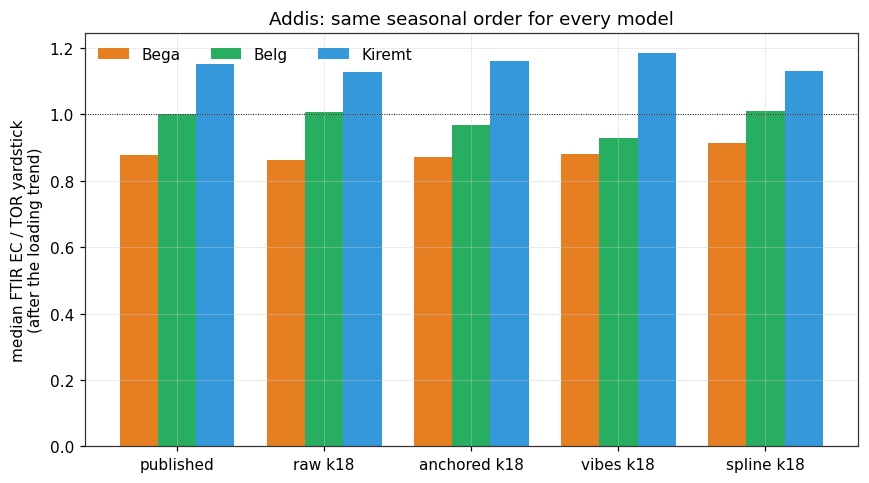

In [3]:
fig, ax = plt.subplots(figsize=(8, 4.5))
mm = m[m.model.isin(MAIN)]
x = np.arange(len(MAIN)); w = 0.26
for i, s in enumerate(SEASONS):
    v = mm[mm.season == s].set_index('model').reindex(MAIN).vs_tor_loading_adjusted
    ax.bar(x + (i - 1) * w, v, w, color=SCOL[s], label=s)
ax.axhline(1, color='k', lw=.6, ls=':')
ax.set_xticks(x, MAIN)
ax.set(ylabel='median FTIR EC / TOR yardstick\n(after the loading trend)', title='Addis: same seasonal order for every model')
ax.legend(frameon=False, ncol=3)
fig.tight_layout(); fig.savefig(FIG / 'fig1_season_by_model.png', dpi=200)

## 2. What changes between seasons

Kiremt carries more organic matter per unit BC by every measure: FTIR OC/BC 1.74 vs 1.02 in Bega, and residual mass/BC
2.9 vs 1.5. Residual mass is PM2.5 − 1.375 SO4 − (2.20 Al + 2.49 Si + 2.42 Fe) − HIPS BC; it doesn't use the FTIR spectrum.
It is a rough organic proxy because it also holds nitrate, extra ammonium, Ca/Ti/Na dust and water.

In [4]:
display(pd.read_csv(T / 'composition.csv').round(2))

,season,n,hips_ug,oc_over_bc,rm_over_bc,pm25_ugm3,so4_ugm3,nsk_ugm3
0,Bega,81,31.12,1.02,1.51,18.15,2.40,0.14
1,Belg,81,32.59,1.17,1.84,19.39,1.42,0.16
2,Kiremt,69,40.24,1.74,2.91,30.06,2.29,0.20


## 3. IMPROVE: FTIR over-reads EC as organics rise, measured with independent TOR OC

This is the organic stand-in from the 2 Nov work, measured directly. In IMPROVE (out-of-site predictions, TOR EC 2–150 µg,
HIPS > 5 µg), FTIR EC / TOR EC rises with TOR OC at fixed loading for **every** baseline. The coefficient is
0.29–0.35 per log unit when loading is measured by TOR EC and 0.15–0.17 when it is measured by HIPS. The OC/EC-balanced
model roughly halves it, as expected if it is learned from the training mix.

covariates,loc + lt,loc + lh,loc + lh + lt
model,,,
raw,0.289,0.159,0.307
spline,0.320,0.163,0.339
vibes,0.328,0.171,0.348
anchored,0.284,0.157,0.301
anchored_noCH,0.287,0.150,0.307
anchored_balanced,0.176,0.115,0.194


model,n
ocec_bin,
"(0.0, 1.5]",34.0
"(1.5, 2.5]",390.0
"(2.5, 4.0]",1448.0
"(4.0, 6.0]",1493.0
"(6.0, 10.0]",1151.0
"(10.0, 100.0]",292.0


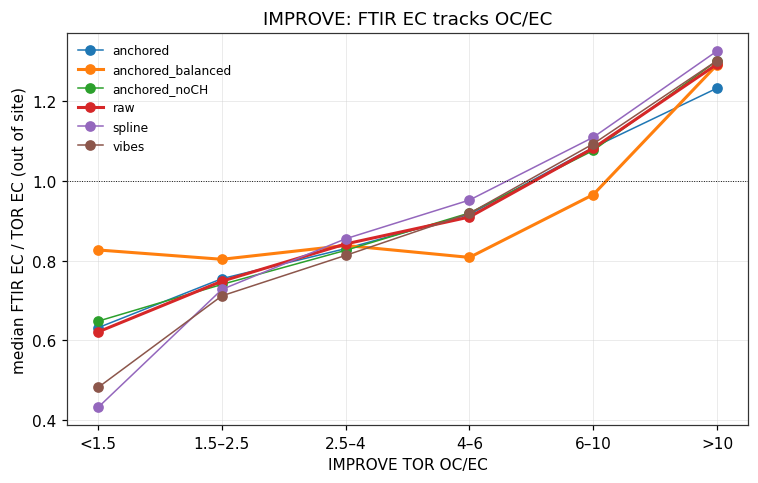

In [5]:
s = pd.read_csv(T / 'improve_organic_slope.csv')
display(s.pivot_table(index='model', columns='covariates', values='coef_loc', sort=False).round(3))
b = pd.read_csv(T / 'improve_ocec_bins.csv')
fig, ax = plt.subplots(figsize=(7, 4.5))
order = ['(0.0, 1.5]', '(1.5, 2.5]', '(2.5, 4.0]', '(4.0, 6.0]', '(6.0, 10.0]', '(10.0, 100.0]']
for nm, g in b.groupby('model'):
    g = g.set_index('ocec_bin').reindex(order)
    ax.plot(range(len(order)), g.ftir_over_tor, marker='o', label=nm, lw=2 if nm in ('raw', 'anchored_balanced') else 1)
ax.axhline(1, color='k', lw=.6, ls=':')
ax.set_xticks(range(len(order)), ['<1.5', '1.5–2.5', '2.5–4', '4–6', '6–10', '>10'])
ax.set(xlabel='IMPROVE TOR OC/EC', ylabel='median FTIR EC / TOR EC (out of site)', title='IMPROVE: FTIR EC tracks OC/EC')
ax.legend(frameon=False, fontsize=8)
fig.tight_layout(); fig.savefig(FIG / 'fig2_improve_ocec.png', dpi=200)
display(b.pivot_table(index='ocec_bin', columns='model', values='n', sort=False).iloc[:, :1].rename(columns=lambda c: 'n'))

## 4. Addis: how much of the season effect do the organic measures absorb?

OLS of log(FTIR EC / TOR yardstick) on season dummies plus covariates. The table shows Belg and Kiremt relative to Bega in %.

* **Residual mass**, which doesn't use the spectrum, roughly halves the Kiremt effect (about +40 % → +20 %). Its
  coefficient (0.26–0.32 for published, raw and anchored) falls inside the IMPROVE range from section 3.
* **FTIR OC** absorbs all of it, but needs a coefficient of 0.7–0.8, two to five times the IMPROVE value. The likeliest
  reason is that FTIR OC and FTIR EC are read from the same spectrum and share an error that rises in Kiremt. So FTIR OC
  "explaining" the season is partly circular.
* Adding nsK and the filter lot barely changes the result. A Kiremt effect of about +20 % remains with the independent
  covariates (CI excludes 0 for every model).

In [6]:
e = pd.read_csv(T / 'season_effects.csv')
cols = ['n', 'Belg_pct', 'Kiremt_pct', 'Kiremt_lo', 'Kiremt_hi', 'Kiremt_p', 'coef_lrm', 'coef_loc', 'r2']
display(e[e.model.isin(MAIN + ['anchored_balanced k12'])].set_index(['model', 'covariates'])[cols].round(2))

n  Belg_pct  Kiremt_pct  Kiremt_lo  Kiremt_hi  Kiremt_p  coef_lrm  coef_loc    r2
model                 covariates                                                                                                                
published             season only                            229     20.80       47.81      38.40      57.86      0.00       NaN       NaN  0.38
                      + loading                              229     20.08       43.57      33.22      54.72      0.00       NaN       NaN  0.38
                      + loading + residual mass              229     12.86       22.04      12.66      32.19      0.00      0.32       NaN  0.51
                      + loading + residual mass + nsK        229     13.87       24.34      14.70      34.80      0.00      0.28       NaN  0.52
                      + loading + residual mass + nsK + lot  229     11.33       17.80       9.29      26.97      0.00      0.25       NaN  0.62
                      + loading + FTIR OC                    229      6.87        1.66      -4.00       7.67      0.57       NaN      0.79  0.77
raw k18               season only                            229     20.27       40.85      32.03      50.25      0.00       NaN       NaN  0.33
                      + loading                              229     19.85       38.48      28.63      49.08      0.00       NaN       NaN  0.33
                      + loading + residual mass              229     12.89       18.36       9.35      28.11      0.00      0.31       NaN  0.46
                      + loading + residual mass + nsK        229     13.90       20.61      11.34      30.65      0.00      0.27       NaN  0.47
                      + loading + residual mass + nsK + lot  229     16.08       21.22      11.85      31.38      0.00      0.26       NaN  0.50
                      + loading + FTIR OC                    229      7.85        1.31      -4.94       7.97      0.69       NaN      0.72  0.69
spline k18            season only                            229     10.64       34.04      23.32      45.70      0.00       NaN       NaN  0.18
                      + loading                              229     10.99       36.08      23.72      49.68      0.00       NaN       NaN  0.18
                      + loading + residual mass              229      2.45       10.33      -0.31      22.11      0.06      0.41       NaN  0.34
                      + loading + residual mass + nsK        229      3.81       13.43       2.43      25.62      0.02      0.35       NaN  0.37
                      + loading + residual mass + nsK + lot  229      5.56       14.47       3.05      27.16      0.01      0.35       NaN  0.38
                      + loading + FTIR OC                    229     -4.53      -12.88     -18.87      -6.45      0.00       NaN      1.02  0.71
vibes k18             season only                            229     15.68       68.47      53.15      85.32      0.00       NaN       NaN  0.35
                      + loading                              229     12.45       46.93      32.62      62.78      0.00       NaN       NaN  0.43
                      + loading + residual mass              229      2.51       15.25       3.57      28.25      0.01      0.48       NaN  0.56
                      + loading + residual mass + nsK        229      3.06       16.56       4.53      29.99      0.01      0.45       NaN  0.56
                      + loading + residual mass + nsK + lot  229      7.76       20.83       8.32      34.79      0.00      0.45       NaN  0.59
                      + loading + FTIR OC                    229     -2.20       -2.85     -11.47       6.61      0.54       NaN      0.95  0.70
anchored k18          season only                            229     17.02       43.20      34.35      52.64      0.00       NaN       NaN  0.35
                      + loading                              229     16.51       40.18      30.34      50.77      0.00       NaN       NaN  0.36
   

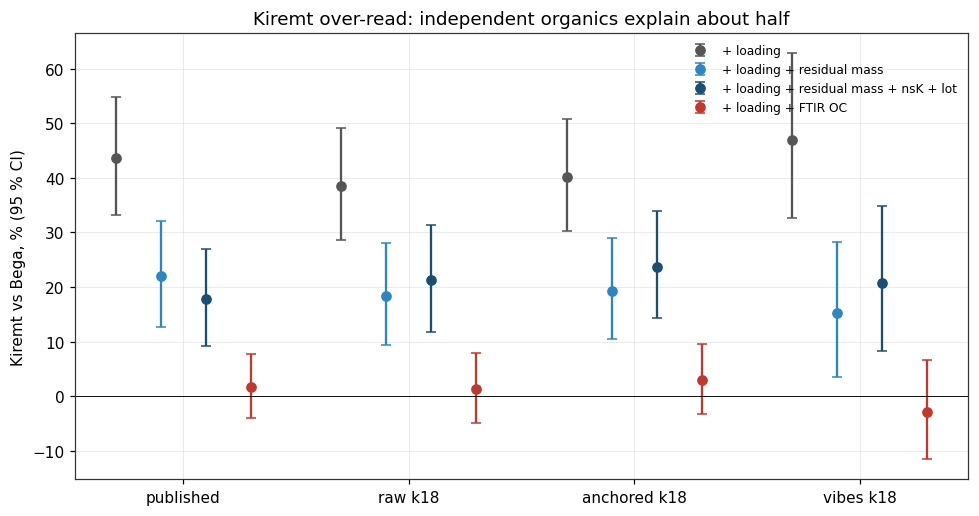

In [7]:
sets = ['+ loading', '+ loading + residual mass', '+ loading + residual mass + nsK + lot', '+ loading + FTIR OC']
show = ['published', 'raw k18', 'anchored k18', 'vibes k18']
fig, ax = plt.subplots(figsize=(9, 4.8))
for j, mdl in enumerate(show):
    g = e[(e.model == mdl)].set_index('covariates').reindex(sets)
    xs = j + np.linspace(-0.3, 0.3, len(sets))
    for xi, (lab, r) in zip(xs, g.iterrows()):
        c = {'+ loading': '#555', '+ loading + residual mass': '#2e86c1',
             '+ loading + residual mass + nsK + lot': '#1b4f72', '+ loading + FTIR OC': '#c0392b'}[lab]
        ax.errorbar(xi, r.Kiremt_pct, yerr=[[r.Kiremt_pct - r.Kiremt_lo], [r.Kiremt_hi - r.Kiremt_pct]], fmt='o', color=c,
                    label=lab if j == 0 else None, capsize=3)
ax.axhline(0, color='k', lw=.6)
ax.set_xticks(range(len(show)), show)
ax.set(ylabel='Kiremt vs Bega, % (95 % CI)', title='Kiremt over-read: independent organics explain about half')
ax.legend(frameon=False, fontsize=8)
fig.tight_layout(); fig.savefig(FIG / 'fig3_kiremt_effect.png', dpi=200)

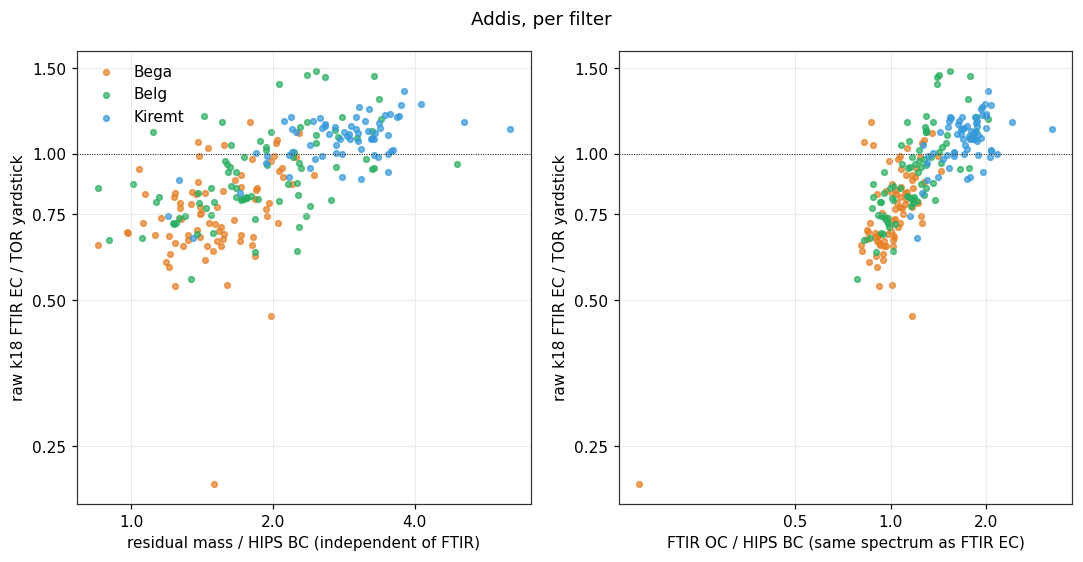

In [8]:
from matplotlib.ticker import FixedLocator, NullLocator, ScalarFormatter
a = pd.read_csv(T / 'addis_filters.csv')
a = a[a.rm_over_bc > 0]
fig, ax = plt.subplots(1, 2, figsize=(10, 5))
for k, (col, lab) in enumerate([('rm_over_bc', 'residual mass / HIPS BC (independent of FTIR)'),
                                ('oc_over_bc', 'FTIR OC / HIPS BC (same spectrum as FTIR EC)')]):
    for s in SEASONS:
        g = a[a.season == s]
        ax[k].scatter(g[col], g['raw k18'] / g.exp_tor_hips, s=14, alpha=.7, color=SCOL[s], label=s)
    ax[k].set_xscale('log'); ax[k].set_yscale('log')
    for axis, ticks in ((ax[k].xaxis, [0.5, 1, 2, 4, 8]), (ax[k].yaxis, [0.25, 0.5, 0.75, 1, 1.5])):
        axis.set_major_locator(FixedLocator(ticks)); axis.set_major_formatter(ScalarFormatter())
        axis.set_minor_locator(NullLocator())
    ax[k].axhline(1, color='k', lw=.6, ls=':')
    ax[k].set(xlabel=lab, ylabel='raw k18 FTIR EC / TOR yardstick')
    ax[k].set_box_aspect(1)
ax[0].legend(frameon=False)
fig.suptitle('Addis, per filter')
fig.tight_layout(); fig.savefig(FIG / 'fig4_addis_organics.png', dpi=200)

## 5. Leave one season out

Fit `log ratio ~ log HIPS + organic proxy` on two seasons and predict the third. With residual mass the held-out level is
reproduced to within about 0.1. Bega comes out lower than predicted and Kiremt higher, which matches the remaining
season effect in section 4.

In [9]:
l = pd.read_csv(T / 'leave_season_out.csv')
display(l[l.model.isin(MAIN)].pivot_table(index=['model', 'proxy'], columns='held_out', values=['observed', 'predicted'], sort=False).round(2))

observed              predicted             
held_out               Bega  Belg Kiremt      Bega  Belg Kiremt
model        proxy                                             
published    lrm       0.83  0.97   1.24      0.95  0.95   1.14
             loc       0.83  0.97   1.24      0.91  0.94   1.31
raw k18      lrm       0.75  0.87   1.09      0.85  0.85   1.02
             loc       0.75  0.87   1.09      0.82  0.84   1.14
spline k18   lrm       0.36  0.40   0.46      0.36  0.38   0.45
             loc       0.36  0.40   0.46      0.34  0.38   0.53
vibes k18    lrm       0.54  0.64   0.96      0.55  0.66   0.83
             loc       0.54  0.64   0.96      0.54  0.65   0.95
anchored k18 lrm       0.73  0.84   1.05      0.81  0.82   0.97
             loc       0.73  0.84   1.05      0.77  0.82   1.08

## 6. Bishoftu: a test site the models were never fitted to, but Bega only

Bishoftu (ETBI) has 21 usable filters, all from Nov–Dec 2025, so the seasonal question can't be tested there. Applying the
Addis composition relation over-predicts Bishoftu for published, raw and anchored (observed about 0.62–0.71, predicted
0.91–1.08). Bishoftu's Bega under-read is therefore larger than its composition implies, whereas spline and VIBES, already low,
are predicted about right. More Bishoftu months are needed before this means much.

In [10]:
display(pd.read_csv(T / 'bishoftu.csv').round(2))

,model,proxy,n,months,observed,predicted_from_addis,addis_bega_observed,oc_over_bc,rm_over_bc
0,published,lrm,21,"2025-11, 2025-12",0.71,1.08,0.83,1.2,2.48
1,published,loc,21,"2025-11, 2025-12",0.71,1.06,0.83,1.2,2.48
2,raw k18,lrm,21,"2025-11, 2025-12",0.62,0.98,0.75,1.2,2.48
3,raw k18,loc,21,"2025-11, 2025-12",0.62,0.97,0.75,1.2,2.48
4,spline k18,lrm,21,"2025-11, 2025-12",0.41,0.48,0.36,1.2,2.48
5,spline k18,loc,21,"2025-11, 2025-12",0.41,0.49,0.36,1.2,2.48
6,vibes k18,lrm,21,"2025-11, 2025-12",0.58,0.60,0.54,1.2,2.48
7,vibes k18,loc,21,"2025-11, 2025-12",0.58,0.60,0.54,1.2,2.48
8,anchored k18,lrm,21,"2025-11, 2025-12",0.62,0.93,0.73,1.2,2.48
9,anchored k18,loc,21,"2025-11, 2025-12",0.62,0.91,0.73,1.2,2.48


## 7. Which spectral windows carry the Kiremt over-read?

The k 18 PLS prediction is linear, so each filter's FTIR EC / TOR yardstick splits exactly into window shares plus an
intercept share. `kiremt_minus_bega` is the difference of season means; `kiremt_adjusted` is the Kiremt coefficient
after log HIPS and log residual mass. Column sums equal the total.

For raw and PTFE-anchored, the Kiremt excess comes from the **organic bands** (aliphatic C–H 3000–2800, 2000–1800 and
C=O/C=C 1800–1500). It is partly cancelled by **2800–2000 cm⁻¹**, where the BC continuum sits and there are almost no organic
bands. That window reads Kiremt *lower* than Bega. Relative to expected EC, then, Kiremt filters carry less continuum and more
organic-band signal. That is the organic stand-in again, and it means a continuum-based EC estimate should show a weaker
season effect. The O–H window (4000–3400) contributes little, so this doesn't support the 3500–4000 cm⁻¹ lead from the
PR #15 review. VIBES and spline remove the continuum, so their small totals are spread differently.

PLS window shares are indicative only: neighbouring channels are correlated and their coefficients offset each other.

kiremt_minus_bega                        kiremt_adjusted                       
model                                        raw anchored  vibes spline             raw anchored  vibes spline
window                                                                                                        
4000-3400 O-H                              0.047    0.068 -0.034 -0.011           0.039    0.049  0.019 -0.001
3400-3000 N-H / O-H / aromatic             0.079    0.005  0.022 -0.032           0.049    0.023  0.038 -0.143
3000-2800 aliphatic C-H                    0.397    0.727  0.044  0.105           0.127    0.240 -0.029  0.169
2800-2000                                 -0.771   -1.038  0.036  0.040          -0.320   -0.441  0.011 -0.006
2000-1800                                  0.321    0.392  0.003  0.014           0.144    0.191 -0.003  0.008
1800-1500 C=O, C=C, N-H                    0.199    0.211 -0.000  0.048           0.091    0.114  0.001  0.001
1500-1425                                 -0.030   -0.058 -0.004  0.013          -0.021   -0.039 -0.027  0.008
below 1425                                 0.123    0.063  0.367    NaN           0.034    0.009  0.098    NaN
intercept                                 -0.067   -0.067 -0.067 -0.067          -0.002   -0.002 -0.002 -0.002
TOTAL                                      0.298    0.304  0.366  0.109           0.140    0.144  0.105  0.034

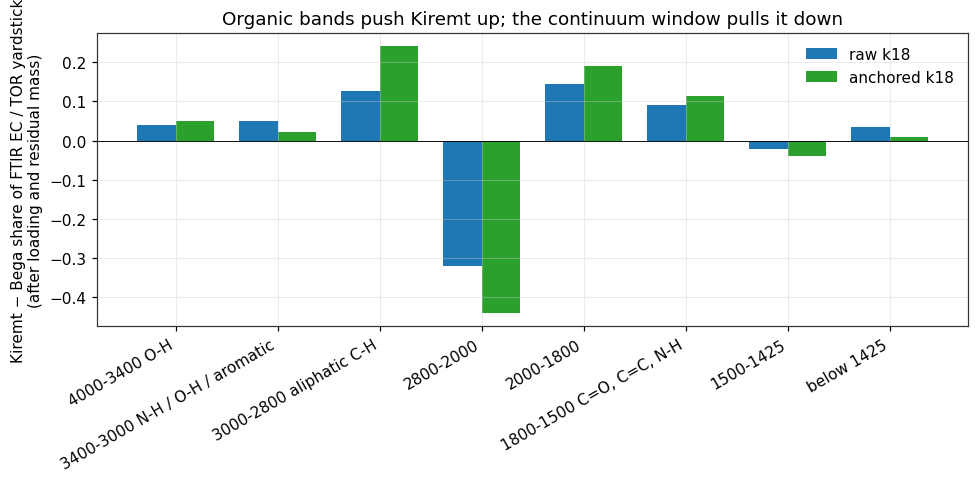

In [11]:
w = pd.read_csv(T / 'season_windows.csv')
display(w.pivot_table(index='window', columns='model', values=['kiremt_minus_bega', 'kiremt_adjusted'], sort=False).round(3))
g = w[(w.model.isin(['raw', 'anchored'])) & ~w.window.isin(['TOTAL', 'intercept'])]
fig, ax = plt.subplots(figsize=(9, 4.5))
wins = list(dict.fromkeys(g.window)); x = np.arange(len(wins))
for i, (mdl, c) in enumerate([('raw', '#1f77b4'), ('anchored', '#2ca02c')]):
    v = g[g.model == mdl].set_index('window').reindex(wins).kiremt_adjusted
    ax.bar(x + (i - .5) * .38, v, .38, color=c, label=f'{mdl} k18')
ax.axhline(0, color='k', lw=.6)
ax.set_xticks(x, wins, rotation=30, ha='right')
ax.set(ylabel='Kiremt − Bega share of FTIR EC / TOR yardstick\n(after loading and residual mass)',
       title='Organic bands push Kiremt up; the continuum window pulls it down')
ax.legend(frameon=False)
fig.tight_layout(); fig.savefig(FIG / 'fig5_season_windows.png', dpi=200)

## 8. Conclusions

1. **The season effect is real.** Against the TOR yardstick, after loading, Addis reads about 0.87 in Bega, 0.97 in Belg
   and 1.13–1.19 in Kiremt, for every baseline. It holds within loading thirds and within lot 251.
2. **About half is the organic stand-in.** IMPROVE models over-read EC as OC/EC rises (shown with independent TOR OC).
   Kiremt has 1.7–1.9× more organic matter per BC than Bega, and an independent residual-mass proxy with the IMPROVE-sized
   coefficient removes about half of the Kiremt effect.
3. **The rest is most likely organic too, but measured poorly.** Only FTIR OC absorbs it, with an implausibly steep
   coefficient, so part of it may be an error FTIR EC and FTIR OC share. But the window split (section 7) puts the remaining
   Kiremt excess in organic bands (C–H, C=O), not in O–H/water. Residual mass is a noisy organic proxy (it holds nitrate
   and water). Noise in a covariate weakens its coefficient and leaves some of the effect assigned to season, so "half" is a
   lower bound for the organic share.
4. **Changing the baseline will not remove it,** as long as the model reads EC through organic bands. Spline and VIBES show
   the same order. The OC/EC-balanced model halves IMPROVE's organic sensitivity but still has a Kiremt effect of +22–27 %.
   The continuum window (2800–2000 cm⁻¹) reads Kiremt lower, which is the reason to expect a continuum-protected
   background to help.

**Next tests.** (a) Repeat with the continuum-protected VIBES runs when they land (the workflow picks up any new `… k18`
column in `network_filters.csv`). (b) A continuum-only EC estimate from 2800–2000 cm⁻¹ by season. (c) Independent OM from
SPARTAN's full reconstruction (with nitrate, ammonium and Ca) instead of the residual-mass approximation. (d) More Bishoftu
months.